# 03 - Model Evaluation

**Task:** predict 30-day readmission (`target = 1`) for diabetic inpatient encounters.

**Evaluation rules**
- **Primary model-selection metric:** Average Precision (AP; area under the precision–recall curve). ROC-AUC is a secondary ranking metric.
- **Operating point:** use the threshold selected on validation data (recomputed from the saved validation predictions; see `run_summary.json`). Report Recall, Precision and F1 at that threshold; do not select a threshold from the test set.
- **Final test set:** 19,802 encounters, 2,216 positives. The train set has 79,541 encounters; the modeling fit/validation split is 63,807/15,734.
- **Comparison tables:** validation metrics at threshold 0.5 are descriptive and are not directly comparable to test metrics calculated at each model's own validation-selected threshold. Ranking metrics (AP/ROC-AUC) do not depend on a threshold.
- **Bootstrap:** resample patients, not individual encounters, when patient IDs are available. This accounts for within-patient correlation.

This notebook intentionally does **not** claim ablation results, SHAP/feature importance results, or verified external-paper baselines unless those analyses and sources have actually been checked. These should be added only after running the corresponding analysis.

In [1]:
from pathlib import Path # Xử lý đường dẫn file/thư mục
import json, warnings, sys # Đọc JSON, quản lý cảnh báo, thao tác hệ thống
import numpy as np # Tính toán số học, mảng dữ liệu
import pandas as pd # Xử lý dữ liệu dạng bảng
import matplotlib.pyplot as plt  # Vẽ biểu đồ
from IPython.display import display # Hiển thị bảng và kết quả trong notebook
from sklearn.metrics import (  # Các chỉ số đánh giá mô hình
    average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    confusion_matrix, brier_score_loss, log_loss, precision_recall_curve,
    roc_curve, auc, classification_report
)  #roc_auc_score, Đo khả năng phân biệt hai lớp
    #precision_score, Tính tỷ lệ dự đoán dương tính đúng
    #recall_score, Tính tỷ lệ phát hiện đúng ca dương tính
    #f1_score, Cân bằng giữa Precision và Recall
    #confusion_matrix,  Tạo ma trận nhầm lẫn
    #brier_score_loss,  Đánh giá độ chính xác của xác suất dự đoán
    #log_loss,   Đánh giá sai số xác suất dự đoán
    #precision_recall_curve, Tính Precision và Recall theo threshold
    #roc_curve,  tính TPR và FPR theo threshold
    #auc,  Tính diện tích dưới đường cong
    #classification_report  Báo cáo các chỉ số phân loại
from sklearn.calibration import calibration_curve # Kiểm tra độ khớp giữa xác suất dự đoán và thực tế
warnings.filterwarnings("ignore") # Ẩn các cảnh báo khi chạy code
SEED = 42 # Cố định seed để kết quả ngẫu nhiên có thể tái lập
N_BOOT = 2000 # Số lần bootstrap để ước lượng độ bất định

In [2]:
# Tìm thư mục gốc của dự án, dù notebook chạy từ thư mục nào
ROOT = Path.cwd().resolve()
# Đi ngược lên thư mục cha đến khi tìm thấy data/ và outputs/
while not ((ROOT / "data").is_dir() and (ROOT / "outputs").is_dir()) and ROOT != ROOT.parent:
    ROOT = ROOT.parent
# Báo lỗi nếu không tìm thấy thư mục gốc dự án
if not ((ROOT / "data").is_dir() and (ROOT / "outputs").is_dir()):
    raise FileNotFoundError("Cannot find project root containing data/ and outputs/. Open this notebook inside the project.")
# Xác định đường dẫn đến dữ liệu và thư mục kết quả
DATA, OUT = ROOT / "data", ROOT / "outputs"
# Xác định thư mục lưu kết quả đánh giá
EVAL = OUT / "evaluation"
# Xác định thư mục lưu biểu đồ và bảng kết quả
FIG, TAB = EVAL / "figures", EVAL / "tables"
# Tạo thư mục nếu chưa tồn tại
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
# Đọc dữ liệu kiểm thử đã làm sạch
test = pd.read_csv(DATA / "test_clean.csv")
# Xác định đường dẫn file chứa dự đoán trên tập test
pred_path = OUT / "test_predictions.csv"
# Kiểm tra file dự đoán có tồn tại không
if pred_path.exists():
    saved = pd.read_csv(pred_path) # Đọc kết quả dự đoán đã lưu
    # Kiểm tra file có đủ hai cột cần thiết
    if {"y_true", "probability"}.issubset(saved.columns):
        y = saved["y_true"].to_numpy(dtype=int) # Nhãn thực tế
        p = saved["probability"].to_numpy(dtype=float) # Xác suất dự đoán
    else:
        # Báo lỗi nếu thiếu cột
        raise ValueError(f"{pred_path} must contain columns y_true and probability.")
else:
    # Báo lỗi nếu chưa chạy bước modeling để xuất dự đoán
    raise FileNotFoundError("Missing outputs/test_predictions.csv. Run the modeling notebook first to export final test predictions.")

# Đảm bảo số dòng dữ liệu và số dự đoán bằng nhau
assert len(test) == len(y) == len(p), "Prediction/test row counts do not match."

# Đảm bảo nhãn thực tế khớp với dữ liệu test
assert np.array_equal(test["target"].to_numpy(dtype=int), y), "Saved predictions are not aligned with test_clean.csv."

# Đảm bảo xác suất dự đoán hợp lệ, nằm trong [0, 1]
assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), "Predicted probabilities must be finite and in [0, 1]."

# Tính lại threshold tối ưu F1 từ dự đoán trên tập validation
# Không lấy threshold từ best_params.json vì file có thể đã cũ
val_path = EVAL / "val_predictions_tuned_catboost.csv"

if not val_path.exists():
    raise FileNotFoundError(
        f"Missing {val_path}. Run 02_modeling first and export validation predictions "
        "with columns y_true, probability."
    )
# Đọc dự đoán trên tập validation
val_pred = pd.read_csv(val_path)
# Kiểm tra file có đủ nhãn thực tế và xác suất dự đoán
if not {"y_true", "probability"}.issubset(val_pred.columns):
    raise ValueError("val_predictions_tuned_catboost.csv must contain y_true, probability.")
# Lấy nhãn thực tế của validation
vy = val_pred["y_true"].to_numpy(dtype=int)
# Lấy xác suất dự đoán của validation
vp = val_pred["probability"].to_numpy(dtype=float)
# Kiểm tra dữ liệu không rỗng và hai mảng có cùng độ dài
if len(vy) == 0 or len(vy) != len(vp):
    raise ValueError("Validation predictions are empty or y_true/probability lengths differ.")
# Đảm bảo nhãn chỉ gồm 0, 1 và có đủ cả hai lớp
if not np.isin(vy, [0, 1]).all() or np.unique(vy).size != 2:
    raise ValueError("Validation y_true must contain both classes coded as 0 and 1.")
# Đảm bảo xác suất validation hợp lệ
if not np.isfinite(vp).all() or ((vp < 0) | (vp > 1)).any():
    raise ValueError("Validation probabilities must be finite and in [0, 1].")
# Tính Precision, Recall và các threshold tương ứng
prec_v, rec_v, thr_v = precision_recall_curve(vy, vp)
# Tính F1 tại từng threshold; tránh chia cho 0
f1_v = np.divide(2*prec_v[:-1]*rec_v[:-1], # Tử số của công thức F1
                  prec_v[:-1]+rec_v[:-1], # Mẫu số của công thức F1
                 out=np.zeros_like(prec_v[:-1]), # Gán 0 nếu phép chia không thực hiện được
                 where=(prec_v[:-1]+rec_v[:-1]) != 0) # Chỉ chia khi mẫu số khác 0

# Chọn threshold có F1 cao nhất trên validation
THR = float(thr_v[int(np.argmax(f1_v))])
# Đồng bộ threshold để các bước sau sử dụng cùng một giá trị
meta_path = OUT / "best_params.json"
# Đọc metadata cũ nếu có, nếu không thì tạo dictionary rỗng
meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
# Lưu threshold vừa tính
meta["threshold"] = THR
# Ghi rõ nguồn lấy threshold
meta["threshold_source"] = "outputs/evaluation/val_predictions_tuned_catboost.csv; max F1 on validation"
# Ghi metadata trở lại file JSON
meta_path.write_text(json.dumps(meta, indent=2))
# Xác định file lưu threshold của các mô hình
thr_path_sync = EVAL / "model_thresholds.json"
# Chỉ cập nhật nếu file đã tồn tại
if thr_path_sync.exists():
    threshold_map = json.loads(thr_path_sync.read_text()) # Đọc các threshold hiện có
    # Cập nhật threshold của Tuned CatBoost
    threshold_map["Tuned CatBoost"] = THR
    # Lưu lại các threshold sau khi cập nhật
    thr_path_sync.write_text(json.dumps(threshold_map, indent=2))
print(f"Project: {ROOT}")
# Đếm số mẫu trong tập train
print(f"Train encounters: {len(pd.read_csv(DATA / 'train_clean.csv')):,}")
# In số mẫu test, số ca dương tính và tỷ lệ dương tính
print(f"Test encounters: {len(y):,} | positive cases: {int(y.sum()):,} ({y.mean():.2%})")
# In số mẫu validation và số ca dương tính
print(f"Validation rows: {len(vy):,} | positives: {int(vy.sum()):,}")
# In tên mô hình và threshold tối ưu được chọn
print(f"Final model: Tuned CatBoost | canonical validation threshold: {THR:.6f}")

Project: /Users/vianhbui/Downloads/diabetes-readmission-prediction
Train encounters: 79,541
Test encounters: 19,802 | positive cases: 2,216 (11.19%)
Validation rows: 15,734 | positives: 1,802
Final model: Tuned CatBoost | canonical validation threshold: 0.145011


## 1. Headline test performance

AP is the primary ranking metric because the positive class is uncommon and AP directly reflects precision–recall performance. ROC-AUC is reported as a complementary ranking metric. Recall, Precision and F1 are calculated at the validation-selected threshold above. No threshold is optimized on the test set.

In [3]:
# Tính các chỉ số đánh giá mô hình tại một threshold
def decision_metrics(y_true, prob, threshold):

    y_true = np.asarray(y_true, dtype=int)  # Chuyển nhãn thực tế thành mảng số nguyên

    # Chuyển xác suất thành nhãn dự đoán theo threshold
    pred_label = (np.asarray(prob) >= threshold).astype(int)

    # Lấy số dự đoán đúng/sai: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(
        y_true, pred_label, labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true, pred_label, zero_division=0
    )  # Tỷ lệ dự đoán dương tính đúng

    recall = recall_score(
        y_true, pred_label, zero_division=0
    )  # Tỷ lệ phát hiện đúng ca dương tính

    f1 = f1_score(
        y_true, pred_label, zero_division=0
    )  # Cân bằng Precision và Recall
    # Trả về các chỉ số đánh giá dưới dạng dictionary
    return {
        "Threshold": threshold,  # Ngưỡng phân loại
        "ROC-AUC": roc_auc_score(y_true, prob),  # Khả năng phân biệt hai lớp
        "AP": average_precision_score(y_true, prob),  # Đánh giá khả năng tìm ca dương tính
        "Recall": recall,  # Tỷ lệ phát hiện ca dương tính
        "Precision": precision,  # Tỷ lệ dự đoán dương tính chính xác
        "F1": f1,  # Điểm cân bằng Precision và Recall
        "Specificity": tn/(tn+fp) if tn+fp else np.nan,  # Tỷ lệ nhận diện đúng ca âm tính
        "Accuracy": (tp+tn)/(tp+tn+fp+fn),  # Tỷ lệ dự đoán đúng toàn bộ
        "Brier": brier_score_loss(y_true, prob),  # Sai số xác suất dự đoán
        "Log loss": log_loss(
            y_true, np.clip(prob, 1e-12, 1-1e-12)
        ),  # Sai số log của xác suất dự đoán
        "TP": tp,  # Ca dương tính dự đoán đúng
        "FP": fp,  # Ca âm tính bị dự đoán nhầm thành dương tính
        "FN": fn,  # Ca dương tính bị dự đoán nhầm thành âm tính
        "TN": tn,  # Ca âm tính dự đoán đúng
        "Flagged %": 100*(tp+fp)/len(y_true)  # Phần trăm bệnh nhân được đánh dấu nguy cơ
    }
# Tạo bảng chỉ số cho mô hình Tuned CatBoost tại threshold đã chọn
headline = pd.DataFrame(
    [decision_metrics(y, p, THR)],
    index=["Tuned CatBoost"]
)
# Chuyển bảng thành dạng dọc và làm tròn 4 chữ số
display(headline.T.rename(columns={0: "Value"}).round(4))
# Lưu bảng chỉ số ra file CSV
headline.to_csv(TAB / "01_headline_metrics.csv")

,Tuned CatBoost
Threshold,0.1450
ROC-AUC,0.6773
AP,0.2444
Recall,0.4305
Precision,0.2168
F1,0.2883
Specificity,0.8040
Accuracy,0.7622
Brier,0.0936
Log loss,0.3272


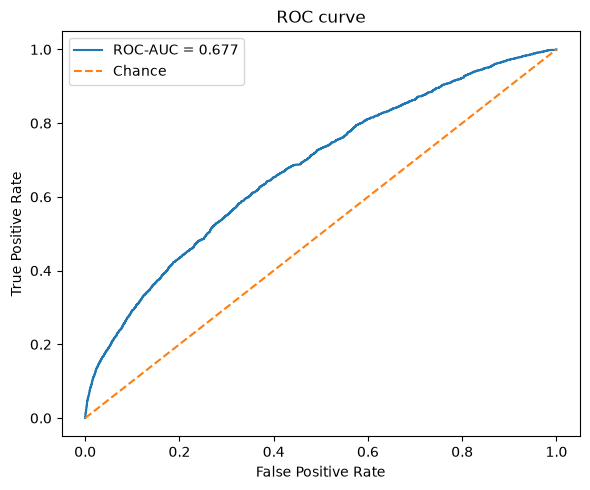

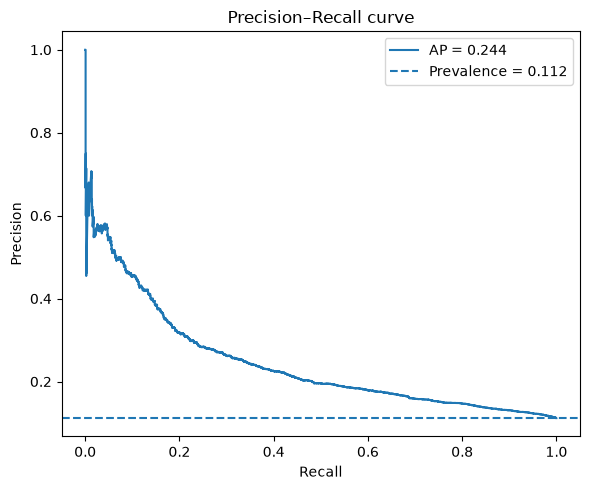

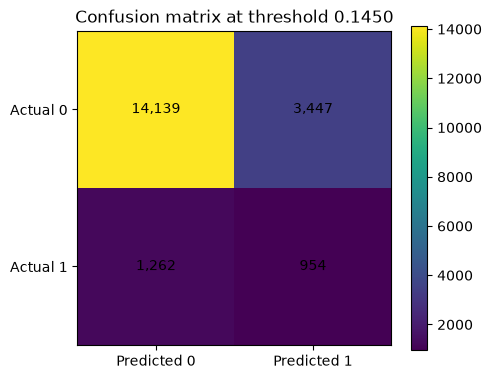

In [4]:
# Vẽ đường cong ROC và Precision–Recall
fpr, tpr, _ = roc_curve(y, p)  # Tính tỷ lệ dương tính giả và tỷ lệ dương tính thật
prec_curve, rec_curve, _ = precision_recall_curve(y, p)  # Tính Precision và Recall theo threshold

# Tạo khung biểu đồ ROC
fig, ax = plt.subplots(figsize=(6, 5))
# Vẽ đường ROC và hiển thị điểm ROC-AUC
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y,p):.3f}")
# Vẽ đường chéo biểu thị mô hình đoán ngẫu nhiên
ax.plot([0,1], [0,1], linestyle="--", label="Chance")
# Đặt tên trục và tiêu đề biểu đồ
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve")
# Hiện chú giải, căn chỉnh và lưu biểu đồ
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_roc_curve.png", dpi=180)  # Lưu biểu đồ ROC với độ phân giải 180 dpi
plt.show()  # Hiển thị biểu đồ

# Tạo khung biểu đồ Precision–Recall
fig, ax = plt.subplots(figsize=(6, 5))
# Vẽ đường Precision–Recall và hiển thị AP
ax.plot(rec_curve, prec_curve, label=f"AP = {average_precision_score(y,p):.3f}")
# Vẽ đường cơ sở bằng tỷ lệ ca dương tính thực tế
ax.axhline(y.mean(), linestyle="--", label=f"Prevalence = {y.mean():.3f}")
# Đặt tên trục và tiêu đề biểu đồ
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve")

# Hiện chú giải, căn chỉnh và lưu biểu đồ
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "01_pr_curve.png", dpi=180)  # Lưu biểu đồ Precision–Recall
plt.show()  # Hiển thị biểu đồ


# Tính số ca TN, FP, FN, TP tại threshold đã chọn
tn, fp, fn, tp = confusion_matrix(y, p >= THR, labels=[0,1]).ravel()

# Tạo khung biểu đồ ma trận nhầm lẫn
fig, ax = plt.subplots(figsize=(5,4))

# Hiển thị ma trận nhầm lẫn dưới dạng hình ảnh
im = ax.imshow([[tn,fp],[fn,tp]], interpolation="nearest")

# Đặt nhãn trục và tiêu đề biểu đồ
ax.set(
    xticks=[0,1],  # Vị trí các nhãn trục ngang
    yticks=[0,1],  # Vị trí các nhãn trục dọc
    xticklabels=["Predicted 0","Predicted 1"],  # Nhãn dự đoán
    yticklabels=["Actual 0","Actual 1"],  # Nhãn thực tế
    title=f"Confusion matrix at threshold {THR:.4f}"  # Hiển thị threshold
)

# Ghi số lượng ca vào từng ô của ma trận
for i,row in enumerate([[tn,fp],[fn,tp]]):
    for j,val in enumerate(row):
        ax.text(j,i,f"{val:,}",ha="center",va="center")  # Căn số vào giữa ô

# Thêm thanh màu, căn chỉnh và lưu biểu đồ
fig.colorbar(im, ax=ax)  # Hiển thị thang màu
fig.tight_layout()  # Tự động căn chỉnh bố cục
fig.savefig(FIG / "01_confusion_matrix.png", dpi=180)  # Lưu ma trận nhầm lẫn
plt.show()  # Hiển thị biểu đồ

## 2. Patient-cluster bootstrap confidence intervals

The same patient may contribute multiple encounters, so an encounter-level bootstrap can understate uncertainty. The code below uses `data/test_patient_groups.csv` if available. If it is absent, it reconstructs patient IDs from `input/diabetic_data.csv` using the same exclusions and `GroupShuffleSplit` seed as the EDA notebook, then verifies row alignment against the cleaned test set.

In [5]:
# Lấy nhóm bệnh nhân tương ứng với tập test
def get_test_patient_groups():
    # Xác định đường dẫn file chứa mã bệnh nhân test
    group_file = DATA / "test_patient_groups.csv"

    # Ưu tiên sử dụng file mã bệnh nhân đã lưu
    if group_file.exists():
        # Đọc mã bệnh nhân từ file CSV
        groups = pd.read_csv(group_file)["patient_nbr"].to_numpy()
        # Kiểm tra số mã bệnh nhân có khớp số dòng test không
        if len(groups) != len(test):
            raise ValueError("test_patient_groups.csv row count does not match test_clean.csv.")
        # Trả về mã bệnh nhân và nguồn dữ liệu
        return groups, "saved data/test_patient_groups.csv"

    # Xác định đường dẫn dữ liệu gốc
    raw_path = ROOT / "input" / "diabetic_data.csv"
    # Báo lỗi nếu không tìm thấy dữ liệu gốc
    if not raw_path.exists():
        raise FileNotFoundError("Patient IDs unavailable: add data/test_patient_groups.csv from the EDA notebook.")

    # Import công cụ chia dữ liệu theo nhóm bệnh nhân
    from sklearn.model_selection import GroupShuffleSplit
    # Đọc dữ liệu gốc và thay dấu ? bằng giá trị thiếu
    raw = pd.read_csv(raw_path).replace("?", np.nan)
    # Loại các trường hợp có mã xuất viện thuộc nhóm cần loại bỏ
    raw = raw[~raw["discharge_disposition_id"].isin([11,13,14,19,20,21])].reset_index(drop=True)

    # Chia dữ liệu theo bệnh nhân, giữ 20% làm tập test
    train_idx, test_idx = next(
        GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
        .split(raw, groups=raw["patient_nbr"])
    )
    # Lấy các dòng thuộc tập test được tái tạo
    raw_test = raw.iloc[test_idx].reset_index(drop=True)

    # Kiểm tra số dòng test có khớp dữ liệu đã xử lý không
    if len(raw_test) != len(test):
        raise ValueError("Reconstructed test rows do not align with test_clean.csv; use saved test_patient_groups.csv generated by EDA.")

    # Kiểm tra nhãn mục tiêu có khớp dữ liệu test không
    if not np.array_equal(
        raw_test["readmitted"].eq("<30").astype(int).to_numpy(),
        test["target"].to_numpy(dtype=int)
    ):
        raise ValueError("Reconstructed patient IDs fail target alignment check.")

    # Kiểm tra thêm các cột nhận diện nếu có trong dữ liệu test
    for col in ["age", "gender"]:
        # Đảm bảo giá trị cột khớp giữa dữ liệu gốc và dữ liệu test
        if col in test and not np.array_equal(
            raw_test[col].astype(str).to_numpy(),
            test[col].astype(str).to_numpy()
        ):
            raise ValueError(f"Reconstructed patient IDs fail {col} alignment check.")

    # Trả về mã bệnh nhân test và nguồn dữ liệu tái tạo
    return raw_test["patient_nbr"].to_numpy(), "reconstructed from raw input and verified"


# Lấy mã bệnh nhân và thông tin nguồn dữ liệu
GROUPS, GROUP_SOURCE = get_test_patient_groups()
# Đảm bảo số nhóm bệnh nhân bằng số dự đoán test
assert len(GROUPS) == len(y)
# In nguồn lấy mã bệnh nhân
print(f"Patient grouping source: {GROUP_SOURCE}")
# In số dòng test và số bệnh nhân duy nhất
print(f"Test encounters={len(y):,}; unique patients={pd.Series(GROUPS).nunique():,}")

Patient grouping source: saved data/test_patient_groups.csv
Test encounters=19,802; unique patients=13,998


In [6]:
# Tính khoảng tin cậy bootstrap bằng cách lấy mẫu theo bệnh nhân
def cluster_bootstrap_ci(y, p, threshold, groups, n_boot=1000, seed=42):
    # Chuyển nhãn, xác suất và mã nhóm thành mảng NumPy
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)

    # Gom các vị trí dòng theo từng bệnh nhân trong một lần xử lý
    # Giúp tránh quét lại toàn bộ dữ liệu cho từng bệnh nhân
    group_rows = [
        idx.to_numpy(dtype=int)
        for _, idx in pd.Series(np.arange(len(groups))).groupby(groups, sort=False)
    ]

    # Khởi tạo bộ sinh số ngẫu nhiên để kết quả có thể tái lập
    rng = np.random.default_rng(seed)
    # Xác định các chỉ số cần tính khoảng tin cậy
    metrics = ["ROC-AUC", "AP", "Recall", "Precision", "F1", "Specificity"]
    # Tạo danh sách lưu kết quả bootstrap của từng chỉ số
    samples = {m: [] for m in metrics}

    # Kiểm tra dữ liệu đầu vào không rỗng và có cùng độ dài
    if len(y) == 0 or len(y) != len(p) or len(y) != len(groups):
        raise ValueError("y, p, and groups must have the same non-zero length.")
    # Đảm bảo có ít nhất 100 lần lấy mẫu bootstrap
    if n_boot < 100:
        raise ValueError("Use at least 100 bootstrap replicates; 2,000 is recommended.")
    # Kiểm tra mã nhóm bệnh nhân không bị thiếu
    if pd.isna(groups).any():
        raise ValueError("Patient group IDs contain missing values.")
    # Đảm bảo tập test có đủ hai lớp mục tiêu
    if np.unique(y).size != 2:
        raise ValueError("The full test set must contain both target classes.")

    # Tính các chỉ số gốc trên toàn bộ tập test
    point = decision_metrics(y, p, threshold)

    # Lặp lại quá trình lấy mẫu bootstrap
    for _ in range(n_boot):
        # Lấy ngẫu nhiên các bệnh nhân có hoàn lại
        selected = rng.integers(0, len(group_rows), size=len(group_rows))
        # Ghép các vị trí dòng của những bệnh nhân được chọn
        ix = np.concatenate([group_rows[j] for j in selected])
        # Tạo mẫu bootstrap gồm nhãn thực tế và xác suất dự đoán
        yb, pb = y[ix], p[ix]

        # Bỏ qua mẫu nếu chỉ còn một lớp mục tiêu
        if np.unique(yb).size < 2:
            continue

        # Tính các chỉ số trên mẫu bootstrap hiện tại
        dm = decision_metrics(yb, pb, threshold)
        # Lưu kết quả của từng chỉ số
        for m in metrics:
            samples[m].append(dm[m])

    # Khởi tạo danh sách lưu bảng khoảng tin cậy
    rows = []
    # Xử lý từng chỉ số đánh giá
    for m in metrics:
        # Chuyển kết quả bootstrap thành mảng số thực
        vals = np.asarray(samples[m], dtype=float)

        # Báo lỗi nếu số mẫu hợp lệ quá ít
        if len(vals) < max(100, int(0.8 * n_boot)):
            raise RuntimeError(
                f"Only {len(vals)} valid bootstrap replicates for {m}; "
                "too many samples lacked both classes. Check target and patient groups."
            )

        # Lưu giá trị gốc, khoảng tin cậy 95% và thông tin lấy mẫu
        rows.append({
            "Metric": m,  # Tên chỉ số đánh giá
            "Estimate": point[m],  # Giá trị tính trên tập test gốc
            "CI low": np.quantile(vals, .025),  # Cận dưới 2,5%
            "CI high": np.quantile(vals, .975),  # Cận trên 97,5%
            "Bootstrap replicates": len(vals),  # Số mẫu bootstrap hợp lệ
            "Resampling unit": "patient"  # Đơn vị lấy mẫu là bệnh nhân
        })

    # Trả về bảng kết quả khoảng tin cậy
    return pd.DataFrame(rows)


# Tính khoảng tin cậy bootstrap theo bệnh nhân
ci = cluster_bootstrap_ci(y, p, THR, GROUPS, N_BOOT, SEED)

# Gộp giá trị ước lượng và khoảng tin cậy thành chuỗi dễ đọc
ci["Estimate [95% CI]"] = ci.apply(
    lambda r: f"{r['Estimate']:.3f} [{r['CI low']:.3f}, {r['CI high']:.3f}]",
    axis=1
)

# Hiển thị các chỉ số cùng khoảng tin cậy 95%
display(ci[["Metric", "Estimate [95% CI]"]].set_index("Metric"))

# Lưu bảng khoảng tin cậy bootstrap ra file CSV
ci.to_csv(TAB / "01_headline_metrics_cluster_bootstrap_ci.csv", index=False)

,Estimate [95% CI]
Metric,
ROC-AUC,"0.677 [0.663, 0.691]"
AP,"0.244 [0.221, 0.268]"
Recall,"0.431 [0.404, 0.458]"
Precision,"0.217 [0.201, 0.232]"
F1,"0.288 [0.270, 0.306]"
Specificity,"0.804 [0.796, 0.811]"


## 3. Baseline reference and model-comparison caveat

A classifier that flags nobody can still achieve high accuracy when positives are rare. The comparison below is illustrative only. Do not interpret the validation table at threshold 0.5 as equivalent to the test comparison at validation-selected thresholds.

**Why can the tables differ?** The modeling notebook's validation table reports threshold-dependent Precision/Recall/F1 at the fixed cutoff 0.5. This evaluation recomputes the operating threshold from the saved validation predictions and records the exact value in `run_summary.json`; it does not rely on a hard-coded threshold. In addition, validation and test are different data splits. AP and ROC-AUC are threshold-free, so they are the appropriate metrics for comparing ranking quality across splits; final performance claims should come from the held-out test set.

In [7]:
# Tính tỷ lệ ca dương tính trong tập test
prev = float(np.mean(y))

# Tạo bảng so sánh mô hình với hai cách dự đoán cơ bản
naive = pd.DataFrame([
    {
        "Model": "Flag nobody",  # Không đánh dấu bệnh nhân nào có nguy cơ
        "Accuracy": 1-prev,  # Độ chính xác bằng tỷ lệ ca âm tính
        "Recall": 0.0,  # Không phát hiện ca dương tính nào
        "Precision": np.nan,  # Không có ca nào được dự đoán dương tính
        "F1": 0.0,  # F1 bằng 0 vì Recall bằng 0
        "AP": prev,  # AP cơ sở bằng tỷ lệ ca dương tính
        "ROC-AUC": 0.5  # Mức tham chiếu tương đương đoán ngẫu nhiên
    },
    {
        "Model": "Flag everybody",  # Đánh dấu tất cả bệnh nhân có nguy cơ
        "Accuracy": prev,  # Độ chính xác bằng tỷ lệ ca dương tính
        "Recall": 1.0,  # Phát hiện được toàn bộ ca dương tính
        "Precision": prev,  # Tỷ lệ dự đoán dương tính đúng bằng tỷ lệ ca dương tính
        "F1": 2*prev/(1+prev),  # Tính F1 từ Precision và Recall
        "AP": prev,  # AP cơ sở bằng tỷ lệ ca dương tính
        "ROC-AUC": 0.5  # Mức tham chiếu tương đương đoán ngẫu nhiên
    },
    {
        "Model": "Tuned CatBoost",  # Mô hình CatBoost đã tinh chỉnh
        "Accuracy": headline.iloc[0]["Accuracy"],  # Lấy Accuracy của mô hình
        "Recall": headline.iloc[0]["Recall"],  # Lấy Recall của mô hình
        "Precision": headline.iloc[0]["Precision"],  # Lấy Precision của mô hình
        "F1": headline.iloc[0]["F1"],  # Lấy F1 của mô hình
        "AP": headline.iloc[0]["AP"],  # Lấy Average Precision của mô hình
        "ROC-AUC": headline.iloc[0]["ROC-AUC"]  # Lấy ROC-AUC của mô hình
    }
])

# Hiển thị bảng so sánh, làm tròn 4 chữ số thập phân
display(naive.round(4).set_index("Model"))

# Lưu bảng so sánh ra file CSV
naive.to_csv(TAB / "02_naive_reference.csv", index=False)

,Accuracy,Recall,Precision,F1,AP,ROC-AUC
Model,,,,,,
Flag nobody,0.8881,0.0000,NaN,0.0000,0.1119,0.5000
Flag everybody,0.1119,1.0000,0.1119,0.2013,0.1119,0.5000
Tuned CatBoost,0.7622,0.4305,0.2168,0.2883,0.2444,0.6773


## 4. Common-test-set model comparison

`outputs/evaluation/model_predictions.csv` contains probabilities for candidate models on the same test encounters. Each model's decision threshold comes from its validation split (`model_thresholds.json`); the tuned model uses the canonical saved threshold. Compare models primarily by AP and ROC-AUC. Recall/Precision/F1 are operating-point metrics and can differ because thresholds differ.

Added canonical Tuned CatBoost probabilities from outputs/test_predictions.csv.


,Model,Threshold,AP,ROC-AUC,Recall,Precision,F1,Specificity,Flagged %
0,CatBoost,0.1279,0.2449,0.6759,0.5036,0.1952,0.2814,0.7384,28.8658
1,Tuned CatBoost,0.1450,0.2444,0.6773,0.4305,0.2168,0.2883,0.8040,22.2250
2,CatBoost + Class Weight,0.5475,0.2307,0.6742,0.4580,0.2092,0.2873,0.7819,24.4975
3,Random Forest,0.1281,0.2240,0.6676,0.5126,0.1926,0.2800,0.7292,29.7899
4,Logistic Regression,0.1271,0.2178,0.6666,0.4901,0.1963,0.2803,0.7472,27.9366
5,Logistic Regression + Class Weight,0.5442,0.2167,0.6679,0.4616,0.1995,0.2786,0.7666,25.8913
6,Random Forest + Class Weight,0.5330,0.2154,0.6631,0.4558,0.1949,0.2731,0.7628,26.1640
7,Decision Tree,0.1351,0.2051,0.6496,0.4517,0.1907,0.2681,0.7584,26.5125
8,Decision Tree + Class Weight,0.6174,0.1974,0.6452,0.2617,0.2272,0.2432,0.8878,12.8926


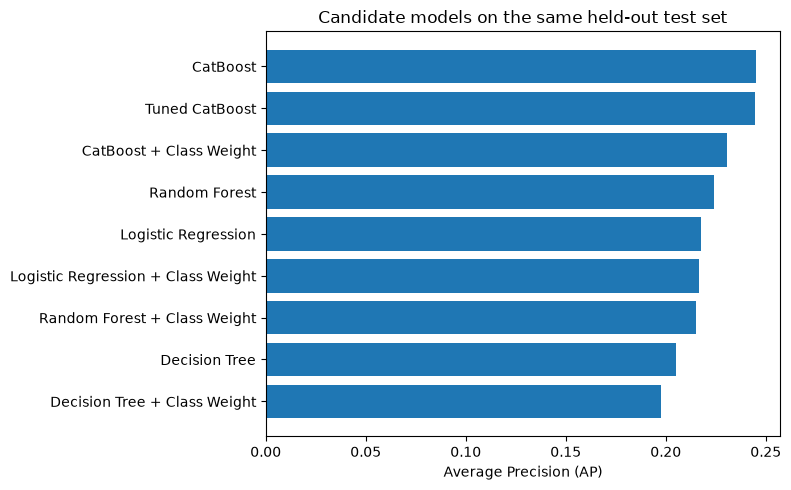

In [8]:
# Xác định đường dẫn file xác suất dự đoán và file threshold của các mô hình
mp_path = EVAL / "model_predictions.csv"
thr_path = EVAL / "model_thresholds.json"

# Chỉ so sánh mô hình khi cả hai file đều tồn tại
if mp_path.exists() and thr_path.exists():
    # Đọc xác suất dự đoán của các mô hình
    mp = pd.read_csv(mp_path)
    # Đọc threshold đã chọn trên tập validation của từng mô hình
    thresholds_by_model = json.loads(thr_path.read_text())

    # Kiểm tra nhãn thực tế và thứ tự dòng có khớp với tập test không
    if "y_true" not in mp or len(mp) != len(y) or not np.array_equal(mp["y_true"].to_numpy(dtype=int), y):
        raise ValueError(
            "model_predictions.csv is not row-aligned with outputs/test_predictions.csv. "
            "Do not compare models until both files refer to the same ordered test rows."
        )

    # Cột Tuned CatBoost trong file cũ có thể đến từ lần huấn luyện khác
    # Dùng xác suất test chính thức để bảng so sánh thống nhất với kết quả headline
    if "Tuned CatBoost" in mp.columns:
        # Lấy xác suất CatBoost đang có trong file so sánh
        old_tuned = mp["Tuned CatBoost"].to_numpy(dtype=float)
        # Kiểm tra xác suất cũ có khớp xác suất chính thức không
        tuned_match = np.allclose(old_tuned, p, rtol=1e-7, atol=1e-8)

        # Cảnh báo nếu xác suất từ hai nguồn khác nhau
        if not tuned_match:
            # Tính chênh lệch tuyệt đối lớn nhất giữa hai bộ xác suất
            max_diff = float(np.max(np.abs(old_tuned - p)))
            # Thông báo sẽ thay cột trong bộ nhớ, không sửa file gốc
            print(
                "WARNING: Tuned CatBoost probabilities in model_predictions.csv differ from "
                "outputs/test_predictions.csv (max absolute difference={max_diff:.6f}). "
                "For this evaluation run, replacing that column in memory with the canonical "
                "outputs/test_predictions.csv probabilities. The original file is not modified."
            )
        # Đồng bộ xác suất CatBoost với file dự đoán chính thức
        mp["Tuned CatBoost"] = p
    else:
        # Thêm xác suất CatBoost chính thức nếu file chưa có cột này
        mp["Tuned CatBoost"] = p

    # Thông báo đã thêm hoặc đồng bộ xác suất CatBoost chính thức
    print("Added canonical Tuned CatBoost probabilities from outputs/test_predictions.csv.")

    # Lấy danh sách cột xác suất, bỏ cột nhãn thực tế
    model_cols = [c for c in mp.columns if c != "y_true"]
    # Tạo danh sách lưu kết quả so sánh
    rows = []

    # Đánh giá lần lượt từng mô hình
    for model_name in model_cols:
        # Lấy xác suất dự đoán của mô hình hiện tại
        prob = mp[model_name].to_numpy(dtype=float)

        # Kiểm tra xác suất có hợp lệ và nằm trong [0, 1] không
        if not np.isfinite(prob).all() or ((prob < 0) | (prob > 1)).any():
            raise ValueError(f"Invalid probabilities in model_predictions.csv column: {model_name}")

        # Dùng threshold đã xác định cho Tuned CatBoost
        if model_name == "Tuned CatBoost":
            threshold = THR
        else:
            # Kiểm tra mô hình có threshold được chọn trên validation không
            if model_name not in thresholds_by_model:
                raise KeyError(
                    f"No validation-selected threshold for '{model_name}' in model_thresholds.json. "
                    "Add/export the threshold from validation; do not select it on test data."
                )
            # Lấy threshold đã lưu cho mô hình
            threshold = float(thresholds_by_model[model_name])

            # Kiểm tra threshold hợp lệ
            if not np.isfinite(threshold) or not 0 <= threshold <= 1:
                raise ValueError(f"Invalid threshold for model '{model_name}': {threshold}")

        # Tính các chỉ số đánh giá của mô hình trên cùng tập test
        dm = decision_metrics(y, prob, threshold)
        # Lưu tên mô hình cùng các chỉ số
        rows.append({"Model": model_name, **dm})

    # Tạo bảng so sánh, ưu tiên AP rồi đến ROC-AUC
    comparison = pd.DataFrame(rows).sort_values(
        ["AP", "ROC-AUC"], ascending=False
    ).reset_index(drop=True)

    # Hiển thị các chỉ số quan trọng để so sánh mô hình
    display(
        comparison[
            ["Model", "Threshold", "AP", "ROC-AUC", "Recall",
             "Precision", "F1", "Specificity", "Flagged %"]
        ].round(4)
    )

    # Lưu bảng so sánh mô hình ra file CSV
    comparison.to_csv(TAB / "03_model_comparison_test.csv", index=False)

    # Tạo khung biểu đồ so sánh AP
    fig, ax = plt.subplots(figsize=(8, 5))
    # Sắp xếp mô hình theo AP tăng dần để vẽ biểu đồ ngang
    plot_df = comparison.sort_values("AP")
    # Vẽ biểu đồ thanh ngang cho AP của từng mô hình
    ax.barh(plot_df["Model"], plot_df["AP"])
    # Đặt tên trục ngang và tiêu đề biểu đồ
    ax.set(
        xlabel="Average Precision (AP)",
        title="Candidate models on the same held-out test set"
    )
    # Căn chỉnh bố cục, lưu biểu đồ và hiển thị
    fig.tight_layout()
    fig.savefig(FIG / "03_model_comparison_ap.png", dpi=180)
    plt.show()

# Thông báo nếu thiếu file cần thiết để so sánh mô hình
else:
    print(
        "Model comparison skipped: outputs/evaluation/model_predictions.csv "
        "or model_thresholds.json is missing. Run src/compare_models.py first."
    )

## 4. Threshold sensitivity (test set used for description only)

This plot describes how metrics change with a threshold; it does **not** select a new threshold. The operating threshold remains the value chosen on validation data.

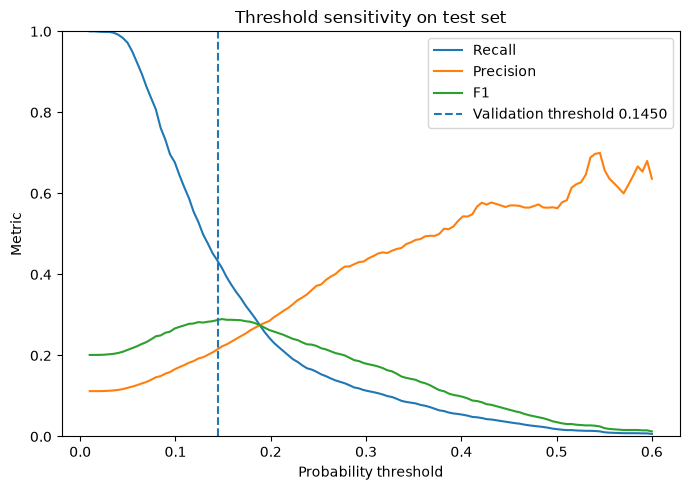

In [9]:
# Tạo 120 threshold từ 0.01 đến 0.60
thresholds = np.linspace(0.01, 0.60, 120)
# Khởi tạo danh sách lưu kết quả theo từng threshold
rows = []

# Đánh giá mô hình tại từng threshold
for t in thresholds:
    # Tính các chỉ số với threshold hiện tại
    d = decision_metrics(y, p, float(t))
    # Lưu threshold và các chỉ số cần theo dõi
    rows.append({
        "Threshold": t,  # Ngưỡng phân loại
        "Recall": d["Recall"],  # Tỷ lệ phát hiện đúng ca dương tính
        "Precision": d["Precision"],  # Tỷ lệ dự đoán dương tính chính xác
        "F1": d["F1"],  # Cân bằng giữa Precision và Recall
        "Flagged %": d["Flagged %"]  # Tỷ lệ bệnh nhân được đánh dấu nguy cơ
    })

# Chuyển kết quả thành DataFrame
sweep = pd.DataFrame(rows)
# Lưu kết quả khảo sát threshold ra CSV
sweep.to_csv(TAB / "04_threshold_sweep.csv", index=False)

# Tạo khung biểu đồ độ nhạy theo threshold
fig, ax = plt.subplots(figsize=(7, 5))
# Vẽ Recall, Precision và F1 theo threshold
for col in ["Recall", "Precision", "F1"]:
    ax.plot(sweep["Threshold"], sweep[col], label=col)

# Đánh dấu threshold được chọn từ tập validation
ax.axvline(THR, linestyle="--", label=f"Validation threshold {THR:.4f}")
# Đặt tên trục, giới hạn trục tung và tiêu đề
ax.set(
    xlabel="Probability threshold",
    ylabel="Metric",
    ylim=(0, 1),
    title="Threshold sensitivity on test set"
)
# Hiển thị chú giải, căn chỉnh, lưu và hiển thị biểu đồ
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "04_threshold_sensitivity.png", dpi=180)
plt.show()

## 5. Calibration

Calibration measures whether predicted probabilities correspond to observed frequencies. The results are descriptive and do not change the operating threshold.

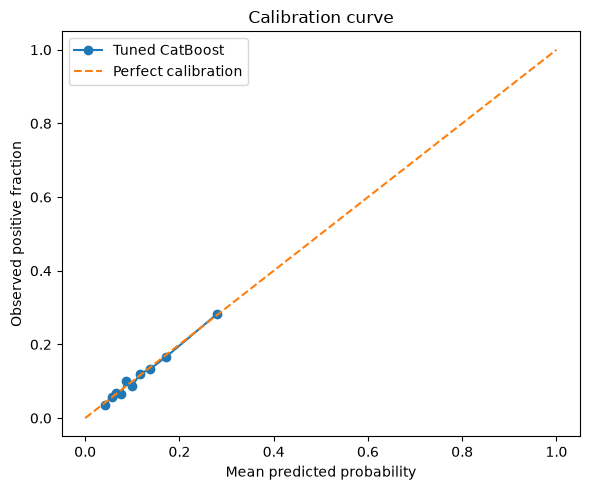

,Brier score,Log loss,Prevalence
0,0.0936,0.3272,0.1119


In [10]:
# Tính tỷ lệ ca dương tính thực tế và xác suất dự đoán trung bình theo từng nhóm
frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")

# Tạo khung biểu đồ calibration
fig, ax = plt.subplots(figsize=(6, 5))
# Vẽ đường calibration của mô hình Tuned CatBoost
ax.plot(mean_pred, frac_pos, marker="o", label="Tuned CatBoost")
# Vẽ đường tham chiếu thể hiện calibration hoàn hảo
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
# Đặt tên trục và tiêu đề biểu đồ
ax.set(
    xlabel="Mean predicted probability",
    ylabel="Observed positive fraction",
    title="Calibration curve"
)
# Hiển thị chú giải, căn chỉnh, lưu và hiển thị biểu đồ
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "07_calibration.png", dpi=180)
plt.show()

# Tạo bảng tổng hợp các chỉ số đánh giá xác suất
cal_summary = pd.DataFrame([{
    "Brier score": brier_score_loss(y, p),  # Đo sai số giữa xác suất dự đoán và nhãn thực tế
    "Log loss": log_loss(y, np.clip(p, 1e-12, 1-1e-12)),  # Đo mức sai lệch của xác suất dự đoán
    "Prevalence": prev  # Tỷ lệ ca dương tính trong tập test
}])

# Hiển thị các chỉ số, làm tròn 4 chữ số thập phân
display(cal_summary.round(4))

# Lưu bảng tổng hợp calibration ra file CSV
cal_summary.to_csv(TAB / "07_calibration_summary.csv", index=False)

## 6. Error and subgroup analysis

These summaries are exploratory. Small groups can produce unstable estimates; do not make fairness or clinical claims from raw subgroup differences alone.

In [11]:
# Chuyển xác suất dự đoán thành nhãn 0 hoặc 1 theo threshold đã chọn
pred_label = (p >= THR).astype(int)

# Sao chép dữ liệu test để tạo bảng phân tích lỗi
errors = test.copy()
# Thêm nhãn thực tế vào bảng
errors["y_true"] = y
# Thêm xác suất dự đoán của mô hình
errors["probability"] = p
# Thêm nhãn dự đoán của mô hình
errors["predicted"] = pred_label

# Phân loại từng dòng thành TP, FN, FP hoặc TN
errors["error_type"] = np.select(
    [
        (y == 1) & (pred_label == 1),  # Thực tế dương tính, dự đoán đúng
        (y == 1) & (pred_label == 0),  # Thực tế dương tính, dự đoán nhầm âm tính
        (y == 0) & (pred_label == 1)   # Thực tế âm tính, dự đoán nhầm dương tính
    ],
    ["TP", "FN", "FP"],  # Nhãn tương ứng với ba trường hợp trên
    default="TN"  # Các trường hợp còn lại là âm tính dự đoán đúng
)

# Lưu nhãn và xác suất dự đoán để phân tích lỗi
errors[["y_true", "probability", "predicted", "error_type"]].to_csv(
    EVAL / "test_error_labels.csv", index=False
)

# Khởi tạo danh sách lưu kết quả đánh giá theo nhóm
subgroup_rows = []

# Xác định các đặc trưng dùng để phân tích hiệu suất theo nhóm
for col in ["age", "gender", "race", "diag_1_group", "discharge_disposition_id"]:
    # Bỏ qua đặc trưng không có trong dữ liệu test
    if col not in test.columns:
        continue

    # Chia dữ liệu thành các nhóm theo giá trị của đặc trưng
    for group, ix in test.groupby(col, dropna=False, observed=True).indices.items():
        # Chuyển vị trí các dòng của nhóm thành mảng NumPy
        ix = np.asarray(ix)
        # Lấy nhãn thực tế, xác suất và nhãn dự đoán của nhóm
        yy = y[ix]
        pp = p[ix]
        ll = pred_label[ix]
        # Đếm số ca dương tính thực tế trong nhóm
        pos = int(yy.sum())

        # Lưu số lượng mẫu và các chỉ số đánh giá của nhóm
        subgroup_rows.append({
            "Feature": col,  # Tên đặc trưng được phân nhóm
            "Group": str(group),  # Giá trị của nhóm
            "n": len(ix),  # Số mẫu trong nhóm
            "Positives": pos,  # Số ca dương tính thực tế
            "Prevalence": float(yy.mean()),  # Tỷ lệ ca dương tính
            "AP": average_precision_score(yy, pp) if np.unique(yy).size > 1 else np.nan,  # AP nếu nhóm có đủ hai lớp
            "ROC-AUC": roc_auc_score(yy, pp) if np.unique(yy).size > 1 else np.nan,  # ROC-AUC nếu nhóm có đủ hai lớp
            "Recall": recall_score(yy, ll, zero_division=0),  # Tỷ lệ phát hiện đúng ca dương tính
            "Precision": precision_score(yy, ll, zero_division=0),  # Tỷ lệ dự đoán dương tính chính xác
            "Flag": "small sample" if len(ix) < 500 or pos < 50 else ""  # Cảnh báo nhóm ít mẫu hoặc ít ca dương tính
        })

# Chuyển kết quả phân tích nhóm thành DataFrame
subgroups = pd.DataFrame(subgroup_rows)

# Hiển thị bảng hiệu suất theo nhóm, làm tròn 3 chữ số
display(subgroups.round(3))

# Lưu kết quả phân tích nhóm ra file CSV
subgroups.to_csv(TAB / "07_subgroup_performance.csv", index=False)

,Feature,Group,n,Positives,Prevalence,AP,ROC-AUC,Recall,Precision,Flag
0,age,[0-10),29,1,0.034,0.036,0.036,0.000,0.000,small sample
1,age,[10-20),138,9,0.065,0.193,0.680,0.222,0.333,small sample
2,age,[20-30),388,60,0.155,0.519,0.873,0.833,0.376,small sample
3,age,[30-40),729,77,0.106,0.334,0.736,0.506,0.255,
4,age,[40-50),1909,202,0.106,0.212,0.673,0.371,0.214,
5,age,[50-60),3469,356,0.103,0.276,0.711,0.416,0.273,
6,age,[60-70),4266,464,0.109,0.225,0.659,0.388,0.209,
7,age,[70-80),5040,587,0.116,0.226,0.666,0.450,0.207,
8,age,[80-90),3287,390,0.119,0.237,0.642,0.438,0.184,
9,age,[90-100),547,70,0.128,0.188,0.524,0.357,0.166,


In [12]:
# Bootstrap theo bệnh nhân dùng chung cho mọi mô hình, để so sánh từng cặp với Tuned CatBoost
KEYS = ["ROC-AUC", "AP", "Recall", "Precision", "F1", "Specificity"]

# Xác suất và threshold của từng mô hình (lấy từ cell so sánh mô hình phía trên)
proba = {m: mp[m].to_numpy(dtype=float) for m in model_cols}
thr_m = {m: (THR if m == "Tuned CatBoost" else float(thresholds_by_model[m])) for m in model_cols}


def cluster_bootstrap_models(y, proba, thr, groups, n_boot, seed=42):
    """Mỗi mẫu bootstrap (chọn bệnh nhân có hoàn lại) được chấm cho mọi mô hình, nên các chênh lệch là theo cặp."""
    y, groups = np.asarray(y), np.asarray(groups)
    group_rows = [idx.to_numpy(dtype=int)
                  for _, idx in pd.Series(np.arange(len(groups))).groupby(groups, sort=False)]
    rng = np.random.default_rng(seed)
    draws = {m: {k: [] for k in KEYS} for m in proba}
    for _ in range(n_boot):
        sel = rng.integers(0, len(group_rows), size=len(group_rows))
        ix = np.concatenate([group_rows[j] for j in sel])
        yb = y[ix]
        if np.unique(yb).size < 2:
            continue
        for m, pr in proba.items():
            dm = decision_metrics(yb, pr[ix], thr[m])
            for k in KEYS:
                draws[m][k].append(dm[k])
    return {m: {k: np.asarray(v) for k, v in d.items()} for m, d in draws.items()}


def _boot_p(d):
    B = len(d)
    return float(min(1.0, 2 * min(((d <= 0).sum() + 1) / (B + 1), ((d >= 0).sum() + 1) / (B + 1))))


def _holm(pvals):
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def pairwise_cluster(y, proba, thr, draws, reference):
    """Mô hình tham chiếu trừ từng mô hình khác: ước lượng, CI 95% và p-value bootstrap, hiệu chỉnh Holm."""
    tests = [("ΔAUC", "ROC-AUC"), ("ΔAP", "AP"), ("ΔF1", "F1"),
             ("ΔRecall", "Recall"), ("ΔSpecificity", "Specificity")]
    ref_est = decision_metrics(np.asarray(y), proba[reference], thr[reference])
    rows = []
    for name, pr in proba.items():
        if name == reference:
            continue
        est = decision_metrics(np.asarray(y), pr, thr[name])
        row = {"Model": name}
        for lab, key in tests:
            d = draws[reference][key] - draws[name][key]
            row[lab] = ref_est[key] - est[key]
            row[lab + " 95% CI"] = f"[{np.quantile(d, .025):+.4f}, {np.quantile(d, .975):+.4f}]"
            row["p " + lab[1:]] = _boot_p(d)
        rows.append(row)
    df = pd.DataFrame(rows)
    for col in [c for c in df.columns if c.startswith("p ")]:
        df[col + " (Holm)"] = _holm(df[col].values)
    return df


print(f"Bootstrap theo bệnh nhân: {len(proba)} mô hình x {N_BOOT:,} lần (có thể mất vài phút)...", flush=True)
draws = cluster_bootstrap_models(y, proba, thr_m, GROUPS, N_BOOT, SEED)
print("Xong.")

Bootstrap theo bệnh nhân: 9 mô hình x 2,000 lần (có thể mất vài phút)...
Xong.


In [13]:
# So sánh từng mô hình với Tuned CatBoost trên cùng các mẫu bootstrap theo bệnh nhân
# Tận dụng lại các mẫu đã lấy, không thực hiện bootstrap bổ sung
pw = pairwise_cluster(y, proba, thr_m, draws, reference="Tuned CatBoost")

# Sao chép bảng kết quả để định dạng khi hiển thị
fmt = pw.copy()

# Tìm các cột chứa giá trị p để định dạng
for c in [c for c in fmt.columns if c.startswith("p ")]:
    # Hiển thị p-value nhỏ hơn 0.001 dưới dạng <0.001, còn lại giữ 3 chữ số thập phân
    fmt[c] = fmt[c].map(lambda v: "<0.001" if v < 0.001 else f"{v:.3f}")

# Hiển thị các chỉ số so sánh và kiểm định thống kê
display(
    fmt[[
        "Model",  # Tên mô hình được so sánh
        "ΔAUC",  # Chênh lệch ROC-AUC
        "ΔAUC 95% CI",  # Khoảng tin cậy 95% của chênh lệch ROC-AUC
        "p AUC (Holm)",  # P-value ROC-AUC sau hiệu chỉnh Holm
        "ΔAP",  # Chênh lệch Average Precision
        "ΔAP 95% CI",  # Khoảng tin cậy 95% của chênh lệch AP
        "p AP (Holm)",  # P-value AP sau hiệu chỉnh Holm
        "ΔF1",  # Chênh lệch F1
        "ΔF1 95% CI",  # Khoảng tin cậy 95% của chênh lệch F1
        "p F1 (Holm)",  # P-value F1 sau hiệu chỉnh Holm
        "ΔRecall",  # Chênh lệch Recall
        "p Recall (Holm)",  # P-value Recall sau hiệu chỉnh Holm
        "ΔSpecificity",  # Chênh lệch Specificity
        "p Specificity (Holm)"  # P-value Specificity sau hiệu chỉnh Holm
    ]].set_index("Model").round(4)  # Đặt tên mô hình làm chỉ mục và làm tròn số
)

# Lưu bảng kiểm định từng cặp mô hình ra file CSV
pw.to_csv(TAB / "03_pairwise_tests_vs_tuned_catboost.csv", index=False)

,ΔAUC,ΔAUC 95% CI,p AUC (Holm),ΔAP,ΔAP 95% CI,p AP (Holm),ΔF1,ΔF1 95% CI,p F1 (Holm),ΔRecall,p Recall (Holm),ΔSpecificity,p Specificity (Holm)
Model,,,,,,,,,,,,,
Logistic Regression,0.0107,"[+0.0055, +0.0159]",0.008,0.0266,"[+0.0169, +0.0355]",0.008,0.0080,"[-0.0006, +0.0167]",0.210,-0.0596,0.008,0.0568,0.008
Decision Tree,0.0278,"[+0.0195, +0.0363]",0.008,0.0393,"[+0.0288, +0.0500]",0.008,0.0202,"[+0.0099, +0.0301]",0.008,-0.0212,0.019,0.0456,0.008
Random Forest,0.0098,"[+0.0051, +0.0144]",0.008,0.0204,"[+0.0120, +0.0303]",0.008,0.0084,"[+0.0001, +0.0162]",0.192,-0.0821,0.008,0.0748,0.008
CatBoost,0.0014,"[-0.0015, +0.0043]",0.355,-0.0005,"[-0.0047, +0.0040]",0.875,0.0070,"[-0.0005, +0.0141]",0.210,-0.0731,0.008,0.0656,0.008
Logistic Regression + Class Weight,0.0094,"[+0.0045, +0.0145]",0.008,0.0277,"[+0.0178, +0.0368]",0.008,0.0097,"[+0.0015, +0.0176]",0.120,-0.0311,0.008,0.0374,0.008
Decision Tree + Class Weight,0.0321,"[+0.0236, +0.0406]",0.008,0.0470,"[+0.0360, +0.0577]",0.008,0.0451,"[+0.0309, +0.0598]",0.008,0.1688,0.008,-0.0838,0.008
Random Forest + Class Weight,0.0143,"[+0.0096, +0.0190]",0.008,0.0290,"[+0.0188, +0.0394]",0.008,0.0153,"[+0.0065, +0.0235]",0.012,-0.0253,0.008,0.0412,0.008
CatBoost + Class Weight,0.0031,"[-0.0009, +0.0070]",0.246,0.0137,"[+0.0071, +0.0205]",0.008,0.0011,"[-0.0059, +0.0079]",0.773,-0.0275,0.008,0.0221,0.008


## 7. What is not claimed in this evaluation

- **Feature-engineering ablation:** not computed in this notebook. To claim the seven engineered features improve performance, fit and compare otherwise identical pipelines with and without those features using the same patient-grouped split/CV and AP as the primary metric.
- **Feature importance / SHAP:** not computed here. Do not write an interpretation of individual feature effects without running a reproducible importance or SHAP analysis on the fitted model.
- **External published baselines:** omitted because the source values and evaluation protocols have not yet been verified from the original papers/pages. Add them only after checking each source and clearly documenting split, target definition, and metric.
- **Environment:** modeling was run in Google Colab and evaluation locally. Record Python and package versions for reproducibility; results may differ slightly across CatBoost/scikit-learn versions.

## 8. Export run summary

In [14]:
# Lấy phiên bản Python và scikit-learn
import platform, sklearn

# Thử lấy phiên bản CatBoost nếu đã cài
try:
    import catboost
    catboost_version = catboost.__version__
# Nếu chưa cài hoặc import lỗi, ghi nhận trạng thái
except Exception:
    catboost_version = "not installed in evaluation environment"

# Tổng hợp thông tin cấu hình và kết quả đánh giá
summary = {
    "final_model": "Tuned CatBoost",  # Mô hình cuối cùng
    "primary_selection_metric": "Average Precision (AP)",  # Chỉ số chính để chọn mô hình
    "threshold_selection": "maximum F1 on validation split; threshold not re-optimized on test",  # Cách chọn ngưỡng
    "operating_threshold": float(THR),  # Ngưỡng phân loại đang dùng
    "train_encounters_expected": 79541,  # Số lượt khám trong tập train dự kiến
    "fit_encounters_expected": 63807,  # Số lượt khám dùng để huấn luyện dự kiến
    "validation_encounters_expected": 15734,  # Số lượt khám trong tập validation dự kiến
    "test_encounters": int(len(y)),  # Số lượt khám trong tập test thực tế
    "test_positive_cases": int(y.sum()),  # Số ca tái nhập viện dương tính
    "test_prevalence": float(y.mean()),  # Tỷ lệ ca dương tính trong tập test
    "test_unique_patients": int(pd.Series(GROUPS).nunique()),  # Số bệnh nhân riêng biệt trong tập test
    "bootstrap_unit": "patient",  # Đơn vị lấy mẫu bootstrap là bệnh nhân
    "bootstrap_replicates_requested": int(N_BOOT),  # Số lần bootstrap yêu cầu
    "bootstrap_replicates_min_valid": int(ci["Bootstrap replicates"].min()),  # Số lần bootstrap hợp lệ tối thiểu
    "test_prediction_source": str(pred_path.relative_to(ROOT)),  # Đường dẫn file dự đoán test
    "validation_prediction_source": str(val_path.relative_to(ROOT)),  # Đường dẫn file dự đoán validation
    "threshold_metric": "F1",  # Chỉ số dùng để chọn ngưỡng
    "python_version": platform.python_version(),  # Phiên bản Python
    "pandas_version": pd.__version__,  # Phiên bản pandas
    "numpy_version": np.__version__,  # Phiên bản NumPy
    "scikit_learn_version": sklearn.__version__,  # Phiên bản scikit-learn
    "catboost_version": catboost_version  # Phiên bản CatBoost
}

# Lưu thông tin tổng kết thành file JSON, thụt lề 2 khoảng trắng
(EVAL / "run_summary.json").write_text(json.dumps(summary, indent=2))

# Hiển thị thông tin tổng kết dưới dạng bảng một cột
display(pd.Series(summary, name="Value").to_frame())

# In đường dẫn thư mục chứa các kết quả đánh giá
print(f"Evaluation outputs saved under: {EVAL}")

,Value
final_model,Tuned CatBoost
primary_selection_metric,Average Precision (AP)
threshold_selection,maximum F1 on validation split; threshold not ...
operating_threshold,0.145011
train_encounters_expected,79541
fit_encounters_expected,63807
validation_encounters_expected,15734
test_encounters,19802
test_positive_cases,2216
test_prevalence,0.111908


Evaluation outputs saved under: /Users/vianhbui/Downloads/diabetes-readmission-prediction/outputs/evaluation
